                                     SARIMAX Results                                      
Dep. Variable:                                  y   No. Observations:                35078
Model:             SARIMAX(1, 0, 1)x(0, 1, 1, 24)   Log Likelihood              -52239.271
Date:                            Tue, 23 Jun 2026   AIC                         104500.541
Time:                                    23:29:16   BIC                         104593.644
Sample:                                01-01-2020   HQIC                        104530.196
                                     - 01-01-2024                                         
Covariance Type:                              opg                                         
                            coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------
PM10                      0.0514      0.000    102.998      0.000       0.050       0.052
SO

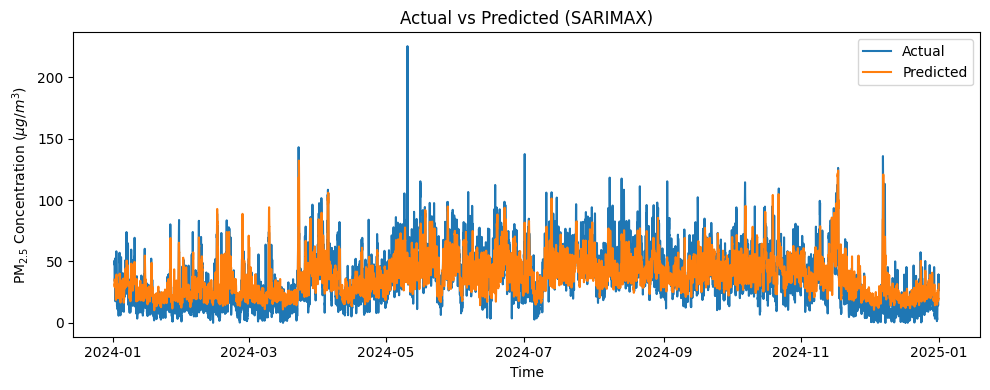

Fitting 5 folds for each of 30 candidates, totalling 150 fits
[LightGBM] [Warning] feature_fraction is set=0.6, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.6
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] feature_fraction is set=0.6, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.6
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.003946 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2040
[LightGBM] [Info] Number of data points in the train set: 35077, number of used features: 8
[LightGBM] [Info] Start training from score 34.842256
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with

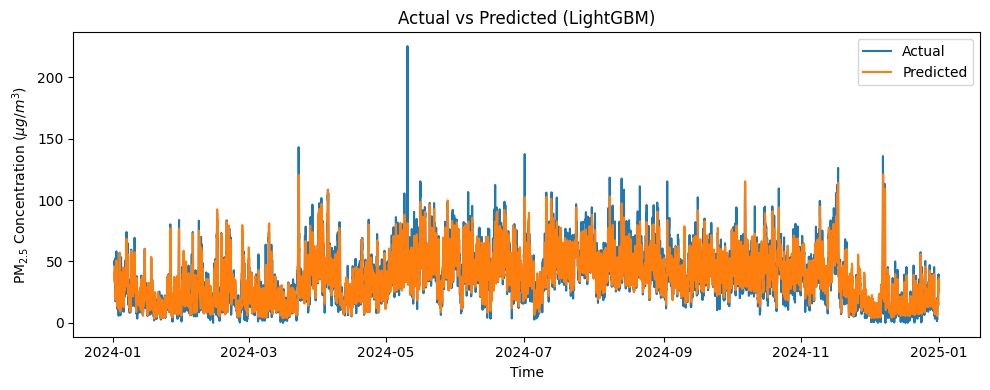

Best alpha (SARIMAX): 0.1
Best beta (LGBM): 0.9

=== TRAIN ENSEMBLE ===
RMSE: 5.2231071189591916
MAE : 3.498899382180905
R2  : 0.9384063036725689

=== TEST ENSEMBLE ===
RMSE: 9.291201887623433
MAE : 6.706917779015234
R2  : 0.8073120749140597


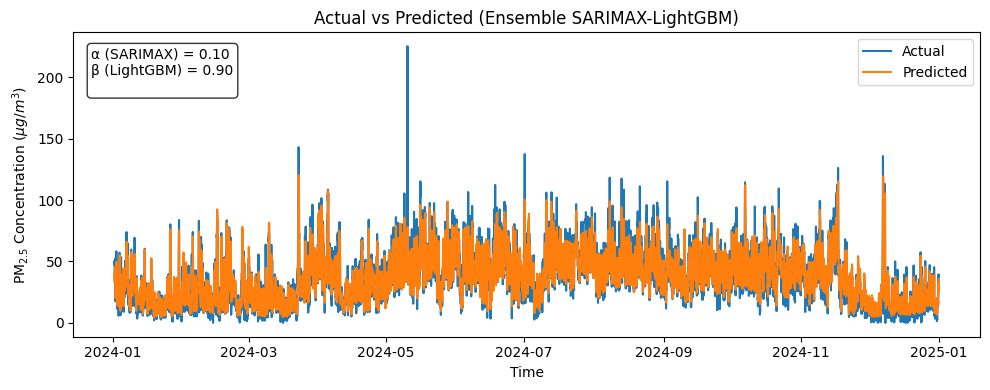

In [ ]:
import pandas as pd
import numpy as np
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.preprocessing import PowerTransformer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")

# =========================
# 1. Load data
# =========================
df_path = "/content/drive/MyDrive/Model/Data Imputasi 2/Data Final Konsentrasi Meteorologi DKI2 Kelapa Gading.xlsx"
df = pd.read_excel(df_path, parse_dates=['datetime'], index_col='datetime')

y = df['PM2.5'].values.reshape(-1, 1)

X = df[['PM10','SO2','CO','O3','NO2',
        'Suhu Udara (°C)',
        'Kecepatan Angin (m/s)']]

# =========================
# 2. Train-test split
# =========================
train_size = int(len(df) * 0.8)

y_train_raw = y[:train_size]
y_test_raw  = y[train_size:]

exog_train = X.iloc[:train_size]
exog_test  = X.iloc[train_size:]

# =========================
# 3. Box-Cox transform
# =========================
if np.any(y_train_raw <= 0):
    y_shift = np.abs(np.min(y_train_raw)) + 1
else:
    y_shift = 0

y_train_pos = y_train_raw + y_shift
y_test_pos  = y_test_raw  + y_shift

pt = PowerTransformer(method='box-cox', standardize=False)

y_train = pt.fit_transform(y_train_pos)
y_test  = pt.transform(y_test_pos)

# =========================
# 4. Fit SARIMAX
# =========================
order = (1, 0, 1)
seasonal_order = (0, 1, 1, 24)

model = SARIMAX(
    y_train.flatten(),
    exog=exog_train,
    order=order,
    seasonal_order=seasonal_order,
    enforce_stationarity=False,
    enforce_invertibility=False
)

result = model.fit(disp=False)
print(result.summary())

# =========================
# 5. Prediksi
# =========================
pred_train = result.predict(
    start=0,
    end=len(y_train)-1,
    exog=exog_train
)

pred_test = result.predict(
    start=len(y_train),
    end=len(y_train)+len(y_test)-1,
    exog=exog_test
)

# =========================
# 6. Inverse Box-Cox
# =========================
pred_train_inv = pt.inverse_transform(
    pred_train.to_numpy().reshape(-1, 1)
).flatten() - y_shift

pred_test_inv = pt.inverse_transform(
    pred_test.to_numpy().reshape(-1, 1)
).flatten() - y_shift

y_train_inv = pt.inverse_transform(y_train).flatten() - y_shift
y_test_inv  = pt.inverse_transform(y_test).flatten() - y_shift

# =========================
# 7. Evaluasi
# =========================
def print_metrics(true, pred, label=""):
    mask = ~np.isnan(true) & ~np.isnan(pred)
    true_clean = true[mask]
    pred_clean = pred[mask]

    print(f"\n=== {label} ===")
    print("MAE :", mean_absolute_error(true_clean, pred_clean))
    print("RMSE:", np.sqrt(mean_squared_error(true_clean, pred_clean)))
    print("R2  :", r2_score(true_clean, pred_clean))

print_metrics(y_train_inv, pred_train_inv, "Train")
print_metrics(y_test_inv, pred_test_inv, "Test")

# =========================
# 8. Plot hasil
# =========================
plt.figure(figsize=(10,4))

plt.plot(df.index[train_size:], y_test_inv, label='Actual')
plt.plot(df.index[train_size:], pred_test_inv, label='Predicted')

plt.title('Actual vs Predicted (SARIMAX)')
plt.ylabel(r'PM$_{2.5}$ Concentration ($\mu g/m^3$)')
plt.xlabel('Time')
plt.legend(loc='upper right')

plt.tight_layout()
plt.show()

# =====================================================
# SIMPAN HASIL SARIMAX
# =====================================================

sarimax_train_pred = pred_train_inv.copy()
sarimax_test_pred  = pred_test_inv.copy()

y_train_actual = y_train_raw.flatten()
y_test_actual  = y_test_raw.flatten()

# ===============================
# 1. IMPORT LIBRARY
# ===============================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from lightgbm import LGBMRegressor

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV

import warnings
warnings.filterwarnings("ignore")


# ===============================
# 2. LOAD DATA
# ===============================
df_path = "/content/drive/MyDrive/Model/Data Imputasi 2/Data Final Konsentrasi Meteorologi DKI2 Kelapa Gading.xlsx"

df = pd.read_excel(
    df_path,
    parse_dates=['datetime'],
    index_col='datetime'
)


# ===============================
# 3. TARGET & FEATURES
# ===============================
y = df['PM2.5']

X = df[[
    'PM10',
    'SO2',
    'CO',
    'O3',
    'NO2',
    'Suhu Udara (°C)',
    'Kecepatan Angin (m/s)',
]]


# ===============================
# 4. TIME SERIES SPLIT
# ===============================
train_size = int(len(df) * 0.8)

X_train, X_test = X.iloc[:train_size], X.iloc[train_size:]
y_train, y_test = y.iloc[:train_size], y.iloc[train_size:]


# ===============================
# 6. BASE MODEL
# ===============================
lgbm = LGBMRegressor(random_state=42)


# ===============================
# 5. PARAMETER GRID (FIXED)
# ===============================
param_grid = {
    'max_depth': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    'num_leaves': [10, 12, 14, 16, 18, 20],
    'learning_rate': [0.01, 0.02, 0.03, 0.05],
    'n_estimators': [1000, 1200, 1500, 1800, 2000],
    'min_child_samples': [10, 20, 30, 40, 50],
    'subsample': [0.7, 0.8, 0.9],
    'feature_fraction': [0.5, 0.6, 0.7, 0.8, 0.9],
    'reg_alpha': [0.01, 0.02, 0.03, 0.04, 0.05],
    'reg_lambda': [0.1, 0.5, 1]
}


# ===============================
# 6. TIME SERIES CV
# ===============================
tscv = TimeSeriesSplit(n_splits=5)


# ===============================
# 7. RANDOM SEARCH CV
# ===============================
search = RandomizedSearchCV(
    estimator=lgbm,
    param_distributions=param_grid,
    n_iter=30,
    cv=tscv,
    scoring='neg_root_mean_squared_error',
    verbose=2,
    random_state=42,
    n_jobs=-1
)


# ===============================
# 8. TRAIN MODEL
# ===============================
search.fit(X_train, y_train)

best_model = search.best_estimator_

print("\n===== BEST PARAMETERS =====")
print(search.best_params_)


# ===============================
# 9. PREDICTION
# ===============================
lgbm_train_pred = best_model.predict(X_train)
lgbm_test_pred  = best_model.predict(X_test)


# ===============================
# 10. EVALUATION FUNCTION
# ===============================
def evaluate(y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    return rmse, mae, r2


train_rmse, train_mae, train_r2 = evaluate(y_train, lgbm_train_pred)
test_rmse, test_mae, test_r2 = evaluate(y_test, lgbm_test_pred)


# ===============================
# 11. RESULT TABLE
# ===============================
hasil = pd.DataFrame({
    'Dataset': ['Train', 'Test'],
    'RMSE': [train_rmse, test_rmse],
    'MAE': [train_mae, test_mae],
    'R2': [train_r2, test_r2]
})

print("\n===== HASIL EVALUASI =====")
print(hasil.round(4))


import matplotlib.pyplot as plt

plt.figure(figsize=(10,4))

plt.plot(
    y_test.index,
    y_test,
    label='Actual'
)

plt.plot(
    y_test.index,
    lgbm_test_pred,
    label='Predicted'
)

plt.title('Actual vs Predicted (LightGBM)')
plt.xlabel('Time')
plt.ylabel(r'PM$_{2.5}$ Concentration ($\mu g/m^3$)')
plt.legend(loc='upper right')

plt.tight_layout()

plt.savefig(
    '/content/drive/MyDrive/Gambar/PDF Gambar/Kelapa Gading/LightGBM_test.pdf',
    dpi=600,
    bbox_inches='tight'
)

plt.show()

min_train = min(len(sarimax_train_pred), len(lgbm_train_pred))
min_test  = min(len(sarimax_test_pred), len(lgbm_test_pred))

sarimax_train = sarimax_train_pred[:min_train]
lgbm_train    = lgbm_train_pred[:min_train]
y_train_ens   = y_train_actual[:min_train]

sarimax_test  = sarimax_test_pred[:min_test]
lgbm_test     = lgbm_test_pred[:min_test]
y_test_ens    = y_test_actual[:min_test]

from sklearn.metrics import mean_squared_error
import numpy as np

best_rmse = np.inf
best_alpha = 0

for alpha in np.arange(0, 1.01, 0.1):
    beta = 1 - alpha

    pred_train = alpha * sarimax_train + beta * lgbm_train

    rmse = np.sqrt(mean_squared_error(y_train_ens, pred_train))

    if rmse < best_rmse:
        best_rmse = rmse
        best_alpha = alpha

best_beta = 1 - best_alpha

print("Best alpha (SARIMAX):", best_alpha)
print("Best beta (LGBM):", best_beta)

ensemble_train = best_alpha * sarimax_train + best_beta * lgbm_train
ensemble_test  = best_alpha * sarimax_test + best_beta * lgbm_test

from sklearn.metrics import mean_absolute_error, r2_score

def evaluate(y_true, y_pred, label=""):
    print(f"\n=== {label} ===")
    print("RMSE:", np.sqrt(mean_squared_error(y_true, y_pred)))
    print("MAE :", mean_absolute_error(y_true, y_pred))
    print("R2  :", r2_score(y_true, y_pred))

evaluate(y_train_ens, ensemble_train, "TRAIN ENSEMBLE")
evaluate(y_test_ens, ensemble_test, "TEST ENSEMBLE")

# =====================================================
# PLOT ENSEMBLE SARIMAX + LGBM (DENGAN α β)
# =====================================================

train_datetime = X_train.index[:min_train]
test_datetime  = X_test.index[:min_test]

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10,4))

textstr = (
    f'α (SARIMAX) = {best_alpha:.2f}\n'
    f'β (LightGBM) = {best_beta:.2f}\n'
)

ax.plot(
    test_datetime,
    y_test_ens,
    label='Actual'
)

ax.plot(
    test_datetime,
    ensemble_test,
    label='Predicted'
)

ax.set_title('Actual vs Predicted (Ensemble SARIMAX-LightGBM)')
ax.set_xlabel('Time')
ax.set_ylabel(r'PM$_{2.5}$ Concentration ($\mu g/m^3$)')
ax.legend(loc='upper right')

ax.text(
    0.02, 0.95,
    textstr,
    transform=ax.transAxes,
    fontsize=10,
    verticalalignment='top',
    bbox=dict(boxstyle='round', facecolor='white', alpha=0.8)
)

plt.tight_layout()

plt.savefig(
    '/content/drive/MyDrive/Gambar/PDF Gambar/Kelapa Gading/ensemble_SARIMAX_LightGBM_test.pdf',
    dpi=600,
    bbox_inches='tight'
)

plt.show()